Andre Esteban Vera

# Reducción de varianza en opciones asiáticas

## Paso 1. Precio exacto de la asiática geométrica

La asiática geométrica usa el promedio geométrico de los precios. Como el
producto de lognormales es lognormal, tiene fórmula cerrada: es Black-Scholes
con dos ajustes.

**Volatilidad ajustada.** El promedio se mueve menos que el precio final:

$$\sigma_a = \frac{\sigma}{\sqrt{3}}$$

**Costo de acarreo ajustado**, con $b = r - q$ (aquí $q = 0$):

$$b_a = \frac{1}{2}\left(b - \frac{\sigma^2}{6}\right)$$

**Fórmulas:**

$$d_1 = \frac{\ln(S_0/K) + (b_a + \sigma_a^2/2)T}{\sigma_a\sqrt{T}}, \qquad d_2 = d_1 - \sigma_a\sqrt{T}$$

$$C = S_0 e^{(b_a - r)T} N(d_1) - K e^{-rT} N(d_2)$$

$$P = K e^{-rT} N(-d_2) - S_0 e^{(b_a - r)T} N(-d_1)$$

Este precio será la **variable de control**: se conoce exacto y se mueve casi
igual que la asiática aritmética, que no tiene fórmula.

### Parámetros y ajustes de la asiática geométrica

In [1]:
import numpy as np
from scipy.stats import norm

S0, K, r, sigma, T = 100, 100, 0.05, 0.20, 1
q = 0
b = r - q

sigma_a = sigma / np.sqrt(3)
b_a = 0.5 * (b - sigma**2 / 6)

print(f"sigma_a = {sigma_a:.6f}")
print(f"b_a     = {b_a:.6f}")

sigma_a = 0.115470
b_a     = 0.021667


### Precio de call y put geométricas (Kemna-Vorst)

In [2]:
d1 = (np.log(S0/K) + (b_a + 0.5*sigma_a**2)*T) / (sigma_a*np.sqrt(T))
d2 = d1 - sigma_a*np.sqrt(T)

call_geo = S0*np.exp((b_a - r)*T)*norm.cdf(d1) - K*np.exp(-r*T)*norm.cdf(d2)
put_geo  = K*np.exp(-r*T)*norm.cdf(-d2) - S0*np.exp((b_a - r)*T)*norm.cdf(-d1)

print(f"d1 = {d1:.6f}   d2 = {d2:.6f}")
print(f"\nCall asiática geométrica : {call_geo:.4f}")
print(f"Put asiática geométrica  : {put_geo:.4f}")

d1 = 0.245374   d2 = 0.129904

Call asiática geométrica : 5.5468
Put asiática geométrica  : 3.4633


### Validación: paridad put-call

In [3]:
izq = call_geo - put_geo
der = S0*np.exp((b_a - r)*T) - K*np.exp(-r*T)

print(f"C - P                     : {izq:.6f}")
print(f"S0·e^((b_a-r)T) - K·e^(-rT) : {der:.6f}")

C - P                     : 2.083487
S0·e^((b_a-r)T) - K·e^(-rT) : 2.083487


### Simulación de 10 trayectorias

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

n, M = 252, 10
dt = T / n

np.random.seed(42)
Z = np.random.normal(0, 1, (M, n))
S = np.zeros((M, n + 1))
S[:, 0] = S0

for t in range(1, n + 1):
    S[:, t] = S[:, t-1] * np.exp((r - 0.5*sigma**2)*dt + sigma*np.sqrt(dt)*Z[:, t-1])

### Media aritmética y geométrica de cada ruta

In [5]:
media_arit = S[:, 1:].mean(axis=1)
media_geo  = np.exp(np.log(S[:, 1:]).mean(axis=1))

tabla = pd.DataFrame({
    "Ruta": np.arange(M),
    "Media aritmética": media_arit,
    "Media geométrica": media_geo,
    "Diferencia": media_arit - media_geo
})
tabla.round(4)

,Ruta,Media aritmética,Media geométrica,Diferencia
0,0,93.6000,93.4301,0.1698
1,1,108.2035,107.9791,0.2243
2,2,88.0323,87.9345,0.0978
3,3,135.6060,133.7083,1.8976
4,4,126.6987,126.0398,0.6589
5,5,109.8488,109.0950,0.7538
6,6,103.9250,103.3401,0.5849
7,7,91.3297,91.2069,0.1228
8,8,95.8567,95.8281,0.0286
9,9,107.2042,107.0081,0.1961


### Gráfica de trayectorias y comparación de medias

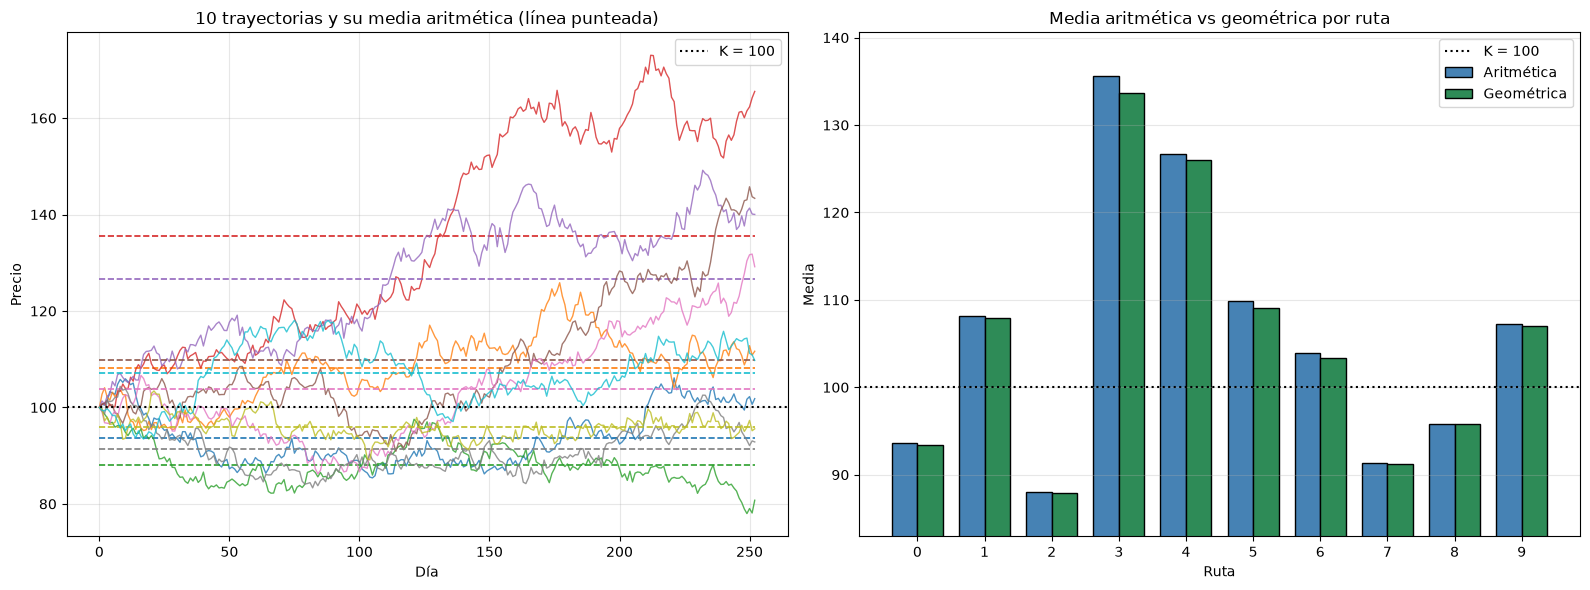

In [6]:
dias = np.arange(n + 1)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for i in range(M):
    linea, = axes[0].plot(dias, S[i], lw=1, alpha=0.8)
    axes[0].hlines(media_arit[i], 0, n, colors=linea.get_color(), ls="--", lw=1.2)

axes[0].axhline(K, color="black", ls=":", lw=1.5, label="K = 100")
axes[0].set_title("10 trayectorias y su media aritmética (línea punteada)")
axes[0].set_xlabel("Día"); axes[0].set_ylabel("Precio")
axes[0].legend(); axes[0].grid(alpha=0.3)

x = np.arange(M)
ancho = 0.38
axes[1].bar(x - ancho/2, media_arit, ancho, color="steelblue", edgecolor="black", label="Aritmética")
axes[1].bar(x + ancho/2, media_geo,  ancho, color="seagreen",  edgecolor="black", label="Geométrica")
axes[1].axhline(K, color="black", ls=":", lw=1.5, label="K = 100")
axes[1].set_ylim(min(media_geo.min(), media_arit.min()) - 5, max(media_arit.max(), media_geo.max()) + 5)
axes[1].set_xticks(x)
axes[1].set_title("Media aritmética vs geométrica por ruta")
axes[1].set_xlabel("Ruta"); axes[1].set_ylabel("Media")
axes[1].legend(); axes[1].grid(alpha=0.3, axis="y")

plt.tight_layout()
plt.show()

---

## Paso 2. Variable de control con 100 rutas

**Opción a valuar:** call asiática **aritmética**, que no tiene fórmula cerrada.

**Variable de control:** call asiática **geométrica**, cuyo precio exacto ya calculamos con Kemna-Vorst ($E[x] = 5.5468$).

Para cada ruta $i$:

- $y_i$: payoff descontado de la call aritmética.
- $x_i$: payoff descontado de la call geométrica.

El estimador corregido es:

$$Y_i(b) = y_i - b\,(x_i - E[x])$$

con el coeficiente óptimo:

$$b^* = \frac{\text{Cov}(x, y)}{\text{Var}(x)}$$

**Intuición:** las dos opciones se mueven casi igual. Si en la muestra la geométrica pagó más que su precio exacto, la aritmética seguramente también salió inflada, y se corrige restando ese exceso. Si pagó menos, se corrige sumando.

### Simulación de 100 trayectorias

In [7]:
n, M = 252, 100
dt = T / n

np.random.seed(42)
Z = np.random.normal(0, 1, (M, n))
S = np.zeros((M, n + 1))
S[:, 0] = S0

for t in range(1, n + 1):
    S[:, t] = S[:, t-1] * np.exp((r - 0.5*sigma**2)*dt + sigma*np.sqrt(dt)*Z[:, t-1])

print(f"Matriz de precios: {S.shape}")

Matriz de precios: (100, 253)


### Media aritmética y geométrica de cada ruta

In [8]:
media_arit = S[:, 1:].mean(axis=1)
media_geo  = np.exp(np.log(S[:, 1:]).mean(axis=1))

print(f"Correlación entre las medias: {np.corrcoef(media_arit, media_geo)[0, 1]:.5f}")
print(f"Rutas con media aritmética > K : {(media_arit > K).sum()}")
print(f"Rutas con media geométrica > K : {(media_geo > K).sum()}")

Correlación entre las medias: 0.99970
Rutas con media aritmética > K : 56
Rutas con media geométrica > K : 53


### Payoffs descontados: y (aritmética) y x (geométrica)

In [9]:
desc = np.exp(-r*T)

y = desc * np.maximum(media_arit - K, 0)   # call aritmética (lo que queremos valuar)
x = desc * np.maximum(media_geo  - K, 0)   # call geométrica (variable de control)

pd.DataFrame({"Ruta": np.arange(M),
              "Media aritmética": media_arit,
              "Media geométrica": media_geo,
              "y (arit)": y,
              "x (geo)": x}).head(10).round(4)

,Ruta,Media aritmética,Media geométrica,y (arit),x (geo)
0,0,93.6000,93.4301,0.0000,0.0000
1,1,108.2035,107.9791,7.8034,7.5900
2,2,88.0323,87.9345,0.0000,0.0000
3,3,135.6060,133.7083,33.8694,32.0643
4,4,126.6987,126.0398,25.3966,24.7698
5,5,109.8488,109.0950,9.3685,8.6514
6,6,103.9250,103.3401,3.7336,3.1772
7,7,91.3297,91.2069,0.0000,0.0000
8,8,95.8567,95.8281,0.0000,0.0000
9,9,107.2042,107.0081,6.8529,6.6663


### Coeficiente b óptimo

In [10]:
b_opt = np.cov(y, x)[0, 1] / np.var(x, ddof=1)
rho   = np.corrcoef(y, x)[0, 1]

print(f"b* = {b_opt:.4f}")
print(f"Correlación entre payoffs = {rho:.5f}")
print(f"Reducción teórica de varianza (1 - rho^2) = {1 - rho**2:.6f}")

b* = 1.0342
Correlación entre payoffs = 0.99972
Reducción teórica de varianza (1 - rho^2) = 0.000557


### Estimador con variable de control

In [11]:
Y_cv = y - b_opt * (x - call_geo)

print(f"Promedio de x en la muestra : {x.mean():.4f}")
print(f"Precio exacto de x, E[x]    : {call_geo:.4f}")
print(f"Desviación de la muestra    : {x.mean() - call_geo:.4f}")
print(f"Corrección aplicada (b·dev) : {-b_opt*(x.mean() - call_geo):+.4f}")

Promedio de x en la muestra : 5.3669
Precio exacto de x, E[x]    : 5.5468
Desviación de la muestra    : -0.1799
Corrección aplicada (b·dev) : +0.1861


### Comparación: Monte Carlo simple vs variable de control

In [12]:
se = lambda v: v.std(ddof=1) / np.sqrt(M)

resultados = pd.DataFrame({
    "Método": ["MC simple", "Variable de control"],
    "Precio call aritmética": [y.mean(), Y_cv.mean()],
    "Error estándar": [se(y), se(Y_cv)],
    "IC 95% inf": [y.mean() - 1.96*se(y), Y_cv.mean() - 1.96*se(Y_cv)],
    "IC 95% sup": [y.mean() + 1.96*se(y), Y_cv.mean() + 1.96*se(Y_cv)],
})
resultados["Ancho IC"] = resultados["IC 95% sup"] - resultados["IC 95% inf"]

vrr = y.var(ddof=1) / Y_cv.var(ddof=1)
print(f"Razón de reducción de varianza (VRR): {vrr:,.0f}")
print(f"Equivale a simular {vrr*M:,.0f} rutas sin control\n")
resultados.round(4)

Razón de reducción de varianza (VRR): 1,794
Equivale a simular 179,425 rutas sin control



,Método,Precio call aritmética,Error estándar,IC 95% inf,IC 95% sup,Ancho IC
0,MC simple,5.5604,0.7351,4.1196,7.0013,2.8817
1,Variable de control,5.7465,0.0174,5.7125,5.7805,0.0680


### Relación entre los payoffs geométrico y aritmético

Cada punto es una ruta. Si la relación es casi una recta, la geométrica explica casi toda la variación de la aritmética, y la pendiente de esa recta es $b^*$.

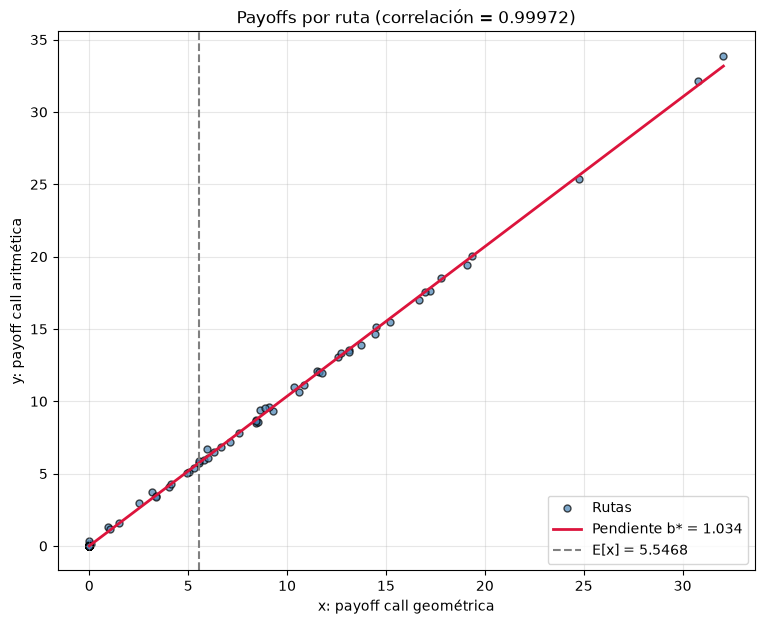

In [13]:
plt.figure(figsize=(9, 7))
plt.scatter(x, y, s=25, alpha=0.7, color="steelblue", edgecolor="black", label="Rutas")

xs = np.linspace(0, x.max(), 100)
plt.plot(xs, y.mean() + b_opt*(xs - x.mean()), color="crimson", lw=2,
         label=f"Pendiente b* = {b_opt:.3f}")

plt.axvline(call_geo, color="gray", ls="--", lw=1.5, label=f"E[x] = {call_geo:.4f}")
plt.xlabel("x: payoff call geométrica")
plt.ylabel("y: payoff call aritmética")
plt.title(f"Payoffs por ruta (correlación = {rho:.5f})")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

### Intervalos de confianza de ambos métodos

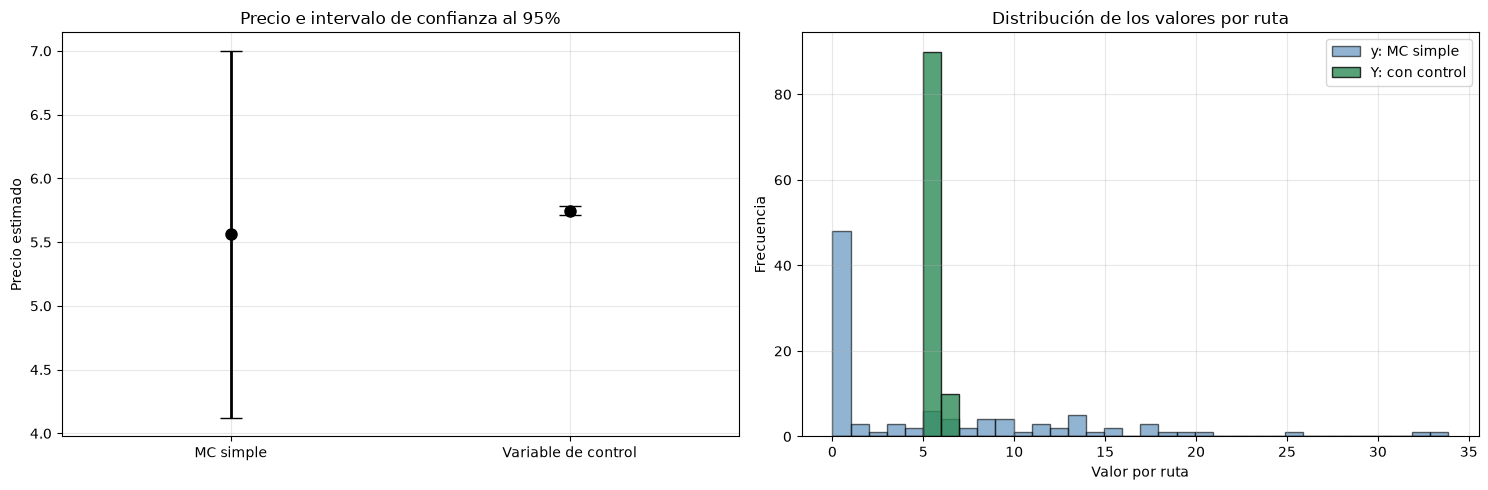

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].errorbar([0, 1], resultados["Precio call aritmética"], yerr=1.96*resultados["Error estándar"],
                 fmt="o", capsize=8, lw=2, ms=8, color="black")
axes[0].set_xticks([0, 1]); axes[0].set_xticklabels(resultados["Método"])
axes[0].set_xlim(-0.5, 1.5)
axes[0].set_ylabel("Precio estimado")
axes[0].set_title("Precio e intervalo de confianza al 95%")
axes[0].grid(alpha=0.3)

bins = np.linspace(0, y.max(), 35)
axes[1].hist(y, bins=bins, alpha=0.6, color="steelblue", edgecolor="black", label="y: MC simple")
axes[1].hist(Y_cv, bins=bins, alpha=0.8, color="seagreen", edgecolor="black", label="Y: con control")
axes[1].set_xlabel("Valor por ruta")
axes[1].set_ylabel("Frecuencia")
axes[1].set_title("Distribución de los valores por ruta")
axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Observación: promedio continuo vs discreto

La fórmula de Kemna-Vorst supone que el promedio se toma en tiempo continuo, pero la simulación promedia 252 cierres diarios. El precio exacto de la geométrica con promedio **discreto** es un poco distinto, y esa diferencia pasa casi completa al estimador porque $b^* \approx 1$.

In [15]:
mu_g  = np.log(S0) + (r - 0.5*sigma**2) * T * (n + 1) / (2*n)
var_g = sigma**2 * T * (n + 1) * (2*n + 1) / (6 * n**2)
s_g   = np.sqrt(var_g)

d1g = (mu_g - np.log(K) + var_g) / s_g
d2g = d1g - s_g
call_geo_d = desc * (np.exp(mu_g + var_g/2)*norm.cdf(d1g) - K*norm.cdf(d2g))

Y_cv_d = y - b_opt * (x - call_geo_d)

print(f"Geométrica continua (Kemna-Vorst) : {call_geo:.4f}")
print(f"Geométrica discreta (252 fechas)  : {call_geo_d:.4f}")
print(f"Diferencia                        : {call_geo_d - call_geo:.4f}")
print(f"\nCall aritmética con control continuo : {Y_cv.mean():.4f}")
print(f"Call aritmética con control discreto : {Y_cv_d.mean():.4f}")
print(f"Error estándar del estimador         : {se(Y_cv):.4f}")

Geométrica continua (Kemna-Vorst) : 5.5468
Geométrica discreta (252 fechas)  : 5.5655
Diferencia                        : 0.0187

Call aritmética con control continuo : 5.7465
Call aritmética con control discreto : 5.7658
Error estándar del estimador         : 0.0174


---

# Conclusiones

**Resultado principal.** Con 100 rutas, la call asiática aritmética vale **5.7465** con variable de control, con un error estándar de 0.0174. El Monte Carlo simple, con las mismas 100 rutas, da 5.5604 con un error estándar de 0.7351.

| Método | Precio | Error estándar | IC 95% |
|---|---|---|---|
| MC simple | 5.5604 | 0.7351 | [4.12, 7.00] |
| Variable de control | **5.7465** | **0.0174** | **[5.71, 5.78]** |

**La reducción de varianza es enorme.** El error estándar bajó 42 veces y la varianza unas 1,800 veces. Con 100 rutas y la geométrica como control se obtiene la precisión que darían cerca de 180,000 rutas de Monte Carlo simple. El intervalo de confianza pasó de casi 3 pesos de ancho a menos de 7 centavos.

**Por qué funciona tan bien.** Los payoffs de la aritmética y la geométrica tienen una correlación de 0.9997. En la gráfica de dispersión los puntos forman prácticamente una recta: si sabes cuánto pagó la geométrica en una ruta, sabes casi exactamente cuánto pagó la aritmética. La varianza que queda después de corregir es $1 - \rho^2 \approx 0.06\%$ de la original.

**Qué hizo la corrección en esta muestra.** En las 100 rutas la geométrica pagó en promedio 5.367, cuando su precio exacto es 5.547: la muestra salió pesimista, con menos escenarios alcistas de lo normal. Como la aritmética se mueve igual, el MC simple también quedó bajo (5.56). El control detectó ese faltante de 0.18 y lo sumó, multiplicado por $b^* = 1.034$, llevando el precio a 5.75. El MC simple no tiene forma de saber que su muestra salió mala; el control sí, porque compara contra un valor que conoce exacto.

**El valor de b.** Salió en 1.034, muy cerca de 1. Eso significa que cada peso de desviación en la geométrica corresponde a poco más de un peso de desviación en la aritmética. Es un poco mayor que 1 porque la media aritmética siempre es mayor o igual que la geométrica, y la brecha crece en las rutas más volátiles, que son justamente las que más pagan.

**Una limitación a tener en cuenta.** La fórmula de Kemna-Vorst supone promedio continuo, pero la simulación promedia 252 fechas discretas. El precio exacto de la geométrica discreta es 5.5655, unos 2 centavos arriba del continuo, y con el control discreto la call aritmética da 5.7658. Con 100 rutas esa diferencia es del mismo tamaño que el error estándar, así que no cambia la conclusión. Pero con muchas más rutas el error estándar seguiría bajando y ese sesgo se volvería la principal fuente de error: llegado ese punto, más simulaciones ya no ayudarían y habría que usar la fórmula discreta.

**Conclusión.** La variable de control es la técnica más efectiva que hemos visto, siempre que exista un control con fórmula cerrada y muy correlacionado con lo que se quiere valuar. En las asiáticas ese control existe y es casi perfecto, por eso con solo 100 rutas se obtiene un precio que el Monte Carlo simple no alcanzaría ni con miles.